
# Airbnb Reviews Data EDA

## Goal

Perform EDA to understand data across six cities before we start sentiment analysis. The goal is to see how much review data we have, how clean it is, and anything we should watch out for when building sentiment features.

Using the latest snapshot for each city.

## Scope

- Analyze the latest priced snapshot for each city.
- Examine review coverage, missing values, duplicates, language distribution, and text lengths.
- Identify potential limitations for sentiment modeling.

## 1. Setup


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="Pandas requires version")

# Locate the repository root
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "strfair").is_dir()
)
sys.path.insert(0, str(ROOT))

# Import existing data loaders
from strfair.data import load_reviews, load_listings, priced_snapshots

# Six project cities
CITIES = [
    "new-york-city",
    "los-angeles",
    "toronto",
    "san-diego",
    "clark-county-nv",
    "jersey-city",
]

# Use the latest priced snapshot available for each city
SNAPSHOTS = {
    city: priced_snapshots(city)[-1]
    for city in CITIES
}

# Output directory
OUT = ROOT / "docs" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Cities:", len(CITIES))
print("Snapshots:")
for city, snapshot in SNAPSHOTS.items():
    print(f"  {city}: {snapshot}")


Project root: c:\Users\orang\Desktop\6242\Projec_REPO
Cities: 6
Snapshots:
  new-york-city: 2026-09-14
  los-angeles: 2026-09-14
  toronto: 2026-09-16
  san-diego: 2026-09-20
  clark-county-nv: 2026-09-20
  jersey-city: 2026-09-21


## 2. Review Coverage & Text Quality

First, checking how many reviews we have in each city, plus missing comments, excesively short reviews, and repeated IDs.


In [3]:
# One pass per city for coverage, text quality, and review lengths
summary_rows, length_rows, length_data = [], [], []
for city in CITIES:
    path = ROOT / "data" / city / SNAPSHOTS[city] / "reviews.csv.gz"
    df = pd.read_csv(path, usecols=["listing_id", "id", "comments"])
    text = df["comments"].fillna("").astype(str).str.strip()
    valid = text.ne("")
    words = text[valid].str.split().str.len()
    per_listing = df.groupby("listing_id").size()

    summary_rows.append({
        "city": city, "total_reviews": len(df),
        "unique_listings": df["listing_id"].nunique(),
        "missing_comments_pct": round((~valid).mean() * 100, 2),
        "short_reviews_pct": round(((words < 5).sum() / len(df)) * 100, 2),
        "extra_duplicate_ids": int(df["id"].duplicated().sum()),
        "avg_reviews_per_listing": round(per_listing.mean(), 1),
        "median_reviews_per_listing": round(per_listing.median(), 1),
    })
    length_rows.append({
        "city": city, "median_words": words.median(),
        "mean_words": round(words.mean(), 1),
        "p90_words": round(words.quantile(.9), 1),
        "over_100_words_pct": round((words > 100).mean() * 100, 2),
    })
    length_data.append(words.to_numpy())

summary_df = pd.DataFrame(summary_rows)
length_df = pd.DataFrame(length_rows)
display(summary_df)


,city,total_reviews,unique_listings,missing_comments_pct,short_reviews_pct,extra_duplicate_ids,avg_reviews_per_listing,median_reviews_per_listing
0,new-york-city,999099,21804,0.03,7.54,0,45.8,12.0
1,los-angeles,1890200,32936,0.02,8.20,0,57.4,18.0
2,toronto,679139,17156,0.01,8.04,0,39.6,14.0
3,san-diego,977802,11099,0.02,5.85,2431,88.1,41.0
4,clark-county-nv,744753,14560,0.04,9.83,5254,51.2,16.0
5,jersey-city,92503,1916,0.02,8.37,0,48.3,21.0


### Key observations

- Review volume and reviews per listing vary across cities.
- Very few reviews are missing comments, some reviews contain fewer than five words.
- San Diego and Clark County have repeated review IDs, might need to investigate. 


## 3. Repeated Review IDs

Checking if the repeated IDs show up under different listings and whether the review text or dates are different.


In [9]:
# Investigate cross-listing review IDs only in cities with duplicates
results = []
for city in summary_df.loc[summary_df["extra_duplicate_ids"] > 0, "city"]:
    path = ROOT / "data" / city / SNAPSHOTS[city] / "reviews.csv.gz"
    df = pd.read_csv(path, usecols=["id", "listing_id", "date", "comments"])
    repeated = df[df.duplicated("id", keep=False)]
    grouped = repeated.groupby("id").agg(
        listings=("listing_id", "nunique"),
        dates=("date", "nunique"),
        comments=("comments", lambda x: x.nunique(dropna=False)),
    )
    results.append({
        "city": city,
        "repeated_review_ids": len(grouped),
        "across_listings": int((grouped["listings"] > 1).sum()),
        "different_dates": int((grouped["dates"] > 1).sum()),
        "different_comments": int((grouped["comments"] > 1).sum()),
    })
display(pd.DataFrame(results))


,city,repeated_review_ids,across_listings,different_dates,different_comments
0,san-diego,982,982,0,0
1,clark-county-nv,2131,2131,0,0


**Finding:** San Diego has 982 repeated review IDs and Clark County has 2,131. Repeated IDs appear across different listings but their dates and comments match. Recommend keeping the raw data as-is for now and flag this when we create listing level sentiment scores.


## 4. Review Length

Compare review word counts across cities.


,city,median_words,mean_words,p90_words,over_100_words_pct
0,new-york-city,31.0,43.9,97.0,9.36
1,los-angeles,28.0,40.1,89.0,7.72
2,toronto,27.0,37.8,83.0,6.42
3,san-diego,31.0,43.7,96.0,9.06
4,clark-county-nv,23.0,34.7,79.0,6.00
5,jersey-city,30.0,42.7,97.0,9.26


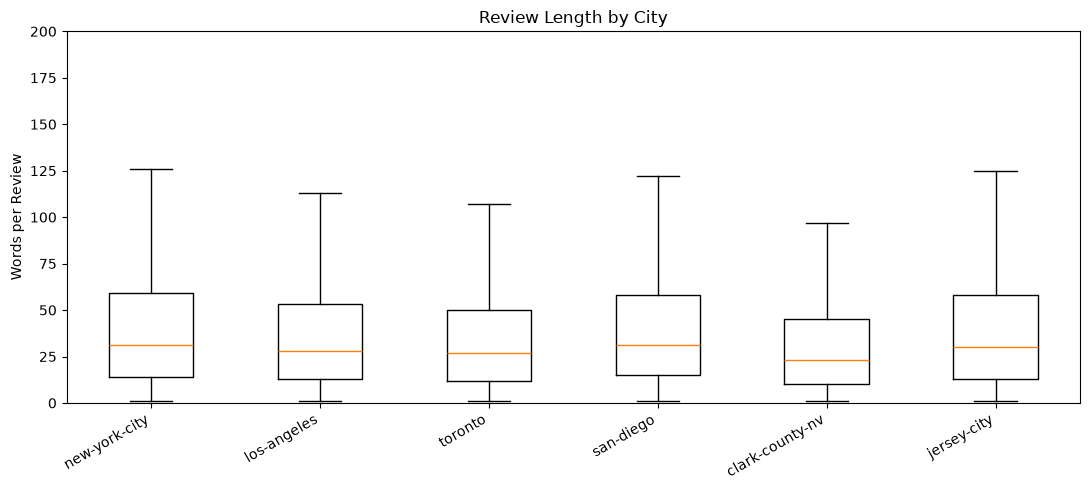

In [5]:
display(length_df)
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(length_data, tick_labels=CITIES, showfliers=False)
ax.set(title="Review Length by City", ylabel="Words per Review", ylim=(0, 200))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


**Finding:** Median review length ranges from 23 to 31 words. Clark County has the shortest median review lengt, although some reviews are much longer.


## 5. Language Distribution

Checking how many reviews are in English using a random sample of up to 20,000 reviews per city (although LA and NYC has the most reviews, close to 1M reviews). Language detection might be less accurate for very short comments.

,English,Non-English,Unknown
city,,,
new-york-city,86.28,13.45,0.27
los-angeles,91.56,8.14,0.30
toronto,88.70,11.01,0.29
san-diego,95.73,4.00,0.26
clark-county-nv,91.94,7.61,0.46
jersey-city,82.63,17.06,0.32


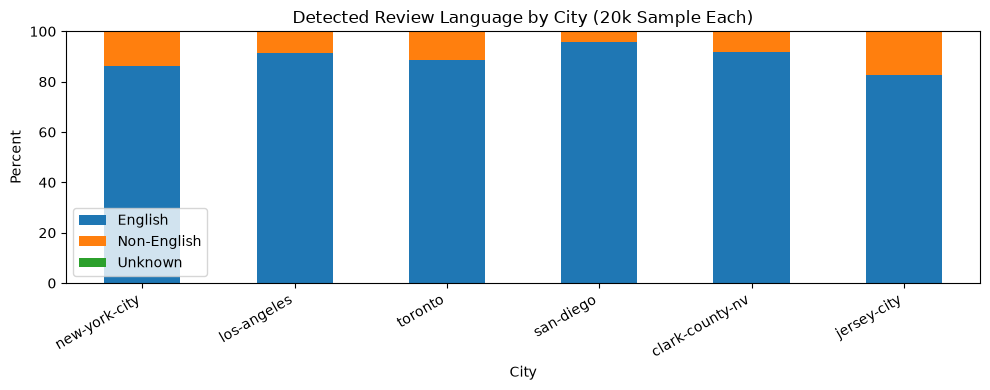

In [6]:
from langdetect import detect, DetectorFactory, LangDetectException
DetectorFactory.seed = 42

def classify_language(comment):
    try:
        return "English" if detect(comment) == "en" else "Non-English"
    except LangDetectException:
        return "Unknown"


language_results = []
for city in CITIES:
    path = ROOT / "data" / city / SNAPSHOTS[city] / "reviews.csv.gz"

    df = pd.read_csv(path, usecols=["comments"])

    text = df["comments"].dropna().astype(str).str.strip()
    text = text[text.ne("")]

    sample = text.sample(n=min(20000, len(text)), random_state=42)

    detected = sample.apply(classify_language)

    counts = detected.value_counts(normalize=True) * 100

    language_results.append({
        "city": city,
        "English": counts.get("English", 0),
        "Non-English": counts.get("Non-English", 0),
        "Unknown": counts.get("Unknown", 0)
    })

language_df = pd.DataFrame(language_results).set_index("city")

display(language_df.round(2))

ax = language_df[["English", "Non-English", "Unknown"]].plot(
    kind="bar", stacked=True, figsize=(10, 4)
)
ax.set(title="Detected Review Language by City (20k Sample Each)", ylabel="Percent", xlabel="City", ylim=(0, 100))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


**Finding:** English accounts for approximately 82%–96% of sampled reviews. For the purpose of using VADER as the baseline model, we'll remove non-English and unknown classified reviews before scoring. 



### Reviews per Listing Distribution

Checking how many reviews each listing has. A sentiment score based on just a couple reviews might be less reliable than one that has a large number of reviews.


In [7]:

review_count_rows = []

for city in CITIES:
    path = ROOT / "data" / city / SNAPSHOTS[city] / "reviews.csv.gz"
    reviews = pd.read_csv(path, usecols=["listing_id", "comments"])

    counts = reviews.loc[
        reviews["comments"].notna()
        & reviews["comments"].astype(str).str.strip().ne("")
    ].groupby("listing_id").size()

    review_count_rows.append({
        "city": city,
        "listings": len(counts),
        "median_reviews": counts.median(),
        "pct_under_5": (counts < 5).mean() * 100,
        "pct_under_10": (counts < 10).mean() * 100,
        "pct_50_plus": (counts >= 50).mean() * 100
    })

review_count_df = pd.DataFrame(review_count_rows).set_index("city")
display(review_count_df.round(1))


,listings,median_reviews,pct_under_5,pct_under_10,pct_50_plus
city,,,,,
new-york-city,21804,12.0,31.2,44.6,25.4
los-angeles,32934,18.0,25.8,38.4,30.3
toronto,17156,14.0,27.7,42.2,23.9
san-diego,11096,41.0,15.7,24.3,45.4
clark-county-nv,14559,16.0,28.9,41.5,29.6
jersey-city,1916,21.0,23.0,34.4,30.0



## 7. Review Relevancy (based on date of reviews)

Understand review age relative to each city's snapshot date to assess whether older reviews should receive less weight in sentiment scoring (since older reviews might be less relevant if the hosts have made improvements).


In [8]:

recency_rows = []

for city in CITIES:
    path = ROOT / "data" / city / SNAPSHOTS[city] / "reviews.csv.gz"
    reviews = pd.read_csv(path, usecols=["date", "comments"])

    snapshot_date = pd.to_datetime(SNAPSHOTS[city])
    dates = pd.to_datetime(reviews["date"], errors="coerce")
    valid = reviews["comments"].notna() & reviews["comments"].astype(str).str.strip().ne("")

    age_days = (snapshot_date - dates[valid]).dt.days
    age_days = age_days[age_days.between(0, 36500)]

    recency_rows.append({
        "city": city,
        "median_age_years": age_days.median() / 365.25,
        "pct_within_1yr": (age_days <= 365).mean() * 100,
        "pct_within_2yrs": (age_days <= 730).mean() * 100,
        "pct_over_3yrs": (age_days > 1095).mean() * 100
    })

recency_df = pd.DataFrame(recency_rows).set_index("city")
display(recency_df.round(1))


,median_age_years,pct_within_1yr,pct_within_2yrs,pct_over_3yrs
city,,,,
new-york-city,3.8,14.6,27.0,62.9
los-angeles,3.0,20.7,36.3,50.3
toronto,2.6,25.1,42.8,43.5
san-diego,2.9,20.5,36.9,49.0
clark-county-nv,2.4,23.6,43.7,39.9
jersey-city,2.0,28.4,49.6,34.0



### Review Recency Findings
- Median review age is around 2–3.8 years across the cities.
- Quite a few reviews are over 3 years old (34%–63%), especially in NYC.
- Only about 15%–28% are from the past year.
- **Implication:** Consider recency weighting to prioritize more recent guest experiences.

### Reviews per Listing Findings
- Median reviews per listing range from 12 (NYC) to 41 (San Diego).
- Around 16%–31% of listings have fewer than 5 reviews.
- San Diego has the highest share of listings with 50+ reviews (~45%).
- **Implication:** We may need to account for listings with very few reviews when calculating sentiment.



### Summary of Key Considerations and Next Steps

- Review count imbalance: 16% - 31% of listings have fewer than 5 reviews (Include review count alongside sentiment and consider weighted scores)
- Older reviews: 34% - 63% of reviews are older than 3 years (Apply weighting to scores)
- Language differences: English reviews account for 82-96% of sampled reviews (Recommend to remove non-English reviews for simplicity)
- Short reviews: Median review length is 23-31 words, roughly 6-10% are under 5 words (Remove empty or unhelpful reviews)
- Duplicate review IDs: San Diego and Clark County have repeated review IDs associated with different listings (Re-visit when aggregating listing level scores before joining with other feature data for price prediction)
- Different reviews patterns by city: San Diego has a median of 41 reviews per listing, compared with 12 in NYC (Compare sentiment distro and feature coverage by city rather assuing all cities behave similarly)

